In [10]:
import os
import sys

# Configura una ruta dummy para evitar el error de HADOOP_HOME en Windows
os.environ['HADOOP_HOME'] = "C:\\hadoop"
os.makedirs("C:\\hadoop\\bin", exist_ok=True)

In [68]:
#Task 1: Apply ETL Operations

import pandas as pd
import numpy as np

# Extraction: Load Source 1 (Raw CDC dataset with missing values)
df_source1 = pd.read_csv('heart_2022_with_nans.csv')
print(f"Source 1 extracted successfully. Shape: {df_source1.shape}")
print("\n--- Source 1 First 5 Columns & Head ---")
print("Columns:", df_source1.columns[:5].tolist())
print(df_source1.head(2))

# Extraction: Load Source 2 (Cleaned cardiovascular dataset)
df_source2 = pd.read_csv('CVD_cleaned.csv')
print(f"\nSource 2 extracted successfully. Shape: {df_source2.shape}")
print("\n--- Source 2 First 5 Columns & Head ---")
print("Columns:", df_source2.columns[:5].tolist())
print(df_source2.head(2))

Source 1 extracted successfully. Shape: (249332, 40)

--- Source 1 First 5 Columns & Head ---
Columns: ['State', 'Sex', 'GeneralHealth', 'PhysicalHealthDays', 'MentalHealthDays']
     State     Sex GeneralHealth  PhysicalHealthDays  MentalHealthDays  \
0  Alabama  Female     Very good                 0.0               0.0   
1  Alabama  Female     Excellent                 0.0               0.0   

                                     LastCheckupTime PhysicalActivities  \
0  Within past year (anytime less than 12 months ...                 No   
1                                                NaN                 No   

   SleepHours RemovedTeeth HadHeartAttack  ... HeightInMeters  \
0         8.0          NaN             No  ...            NaN   
1         6.0          NaN             No  ...            1.6   

  WeightInKilograms    BMI AlcoholDrinkers HIVTesting FluVaxLast12  \
0               NaN    NaN              No         No          Yes   
1             68.04  26.57          

In [69]:
# Handling missing values

import pandas as pd
import numpy as np

# Load both datasets
df_source1 = pd.read_csv('CVD_cleaned.csv')
df_source2 = pd.read_csv('heart_2022_with_nans.csv')

# ==========================================
# SOURCE 1: CVD_cleaned.csv (Handling Missing Values)
# ==========================================
print("--- SOURCE 1: Missing values before cleaning ---")
print(df_source1[['BMI', 'Weight_(kg)', 'Height_(cm)']].isna().sum())

# Impute missing values using robust statistical measures (mean and median)
df_source1['BMI'] = df_source1['BMI'].fillna(df_source1['BMI'].mean())
df_source1['Weight_(kg)'] = df_source1['Weight_(kg)'].fillna(df_source1['Weight_(kg)'].mean())
df_source1['Height_(cm)'] = df_source1['Height_(cm)'].fillna(df_source1['Height_(cm)'].median())

print("\n--- SOURCE 1: Missing values after cleaning ---")
print(df_source1[['BMI', 'Weight_(kg)', 'Height_(cm)']].isna().sum())


# ==========================================
# SOURCE 2: heart_2022_with_nans.csv (Handling Missing Values)
# ==========================================
print("\n--- SOURCE 2: Missing values before cleaning ---")
print(df_source2[['SleepHours', 'BMI', 'WeightInKilograms']].isna().sum())

# Impute missing values using robust statistical measures (mean and median)
df_source2['SleepHours'] = df_source2['SleepHours'].fillna(df_source2['SleepHours'].median())
df_source2['BMI'] = df_source2['BMI'].fillna(df_source2['BMI'].mean())
df_source2['WeightInKilograms'] = df_source2['WeightInKilograms'].fillna(df_source2['WeightInKilograms'].mean())

print("\n--- SOURCE 2: Missing values after cleaning ---")
print(df_source2[['SleepHours', 'BMI', 'WeightInKilograms']].isna().sum())

--- SOURCE 1: Missing values before cleaning ---
BMI            15202
Weight_(kg)    15409
Height_(cm)    15324
dtype: int64

--- SOURCE 1: Missing values after cleaning ---
BMI            0
Weight_(kg)    0
Height_(cm)    0
dtype: int64

--- SOURCE 2: Missing values before cleaning ---
SleepHours            2917
BMI                  27054
WeightInKilograms    23218
dtype: int64

--- SOURCE 2: Missing values after cleaning ---
SleepHours           0
BMI                  0
WeightInKilograms    0
dtype: int64


In [70]:
# Correction snippet: Handle missing values in general_health and unify safely
unified_df['general_health'] = unified_df['general_health'].fillna('Unknown')

# Verify that no NaNs remain
print("Remaining NaN values:", unified_df['general_health'].isna().sum())
print(unified_df['general_health'].value_counts(dropna=False))

Remaining NaN values: 0
general_health
Very Good    188760
Good         171151
Excellent     93345
Fair          67026
Poor          21670
Unknown       16234
Name: count, dtype: int64


In [81]:
# Remove duplicate records from both sources
initial_len_s1 = len(df_source1)
df_source1 = df_source1.drop_duplicates()
print(f"Duplicates removed from Source 1: {initial_len_s1 - len(df_source1)}")

initial_len_s2 = len(df_source2)
df_source2 = df_source2.drop_duplicates()
print(f"Duplicates removed from Source 2: {initial_len_s2 - len(df_source2)}")

Duplicates removed from Source 1: 60
Duplicates removed from Source 2: 84


In [82]:
# Rename columns for consistency across datasets
df_source1 = df_source1.rename(columns={
    'General_Health': 'general_health',
    'Sex': 'gender',
    'Weight_(kg)': 'weight_kg',
    'Height_(cm)': 'height_cm'
})

df_source2 = df_source2.rename(columns={
    'GeneralHealth': 'general_health',
    'Sex': 'gender',
    'WeightInKilograms': 'weight_kg',
    'HeightInMeters': 'height_m'
})

In [83]:
# Validate and cast data types to appropriate formats
df_source1['BMI'] = df_source1['BMI'].astype(float)
df_source1['weight_kg'] = df_source1['weight_kg'].astype(float)

df_source2['BMI'] = df_source2['BMI'].astype(float)
df_source2['weight_kg'] = df_source2['weight_kg'].astype(float)

print("Validated data types for Source 1:\n", df_source1[['BMI', 'weight_kg']].dtypes)

Validated data types for Source 1:
 BMI          float64
weight_kg    float64
dtype: object


In [84]:
# Create a derived field to categorize BMI levels
def categorize_bmi(bmi):
    if pd.isna(bmi):
        return 'Unknown'
    elif bmi < 18.5:
        return 'Underweight'
    elif bmi < 25.0:
        return 'Normal'
    elif bmi < 30.0:
        return 'Overweight'
    else:
        return 'Obese'

df_source1['bmi_category'] = df_source1['BMI'].apply(categorize_bmi)
df_source2['bmi_category'] = df_source2['BMI'].apply(categorize_bmi)

print("Derived field sample (bmi_category):")
print(df_source1[['BMI', 'bmi_category']].head(3))

Derived field sample (bmi_category):
     BMI bmi_category
0  14.54  Underweight
1  28.29   Overweight
2  33.47        Obese


In [85]:
# Loading: Select common matching columns and integrate into a unified structure
common_columns = ['gender', 'general_health', 'BMI', 'weight_kg', 'bmi_category']

df_s1_subset = df_source1[common_columns].copy()
df_s2_subset = df_source2[common_columns].copy()

unified_df = pd.concat([df_s1_subset, df_s2_subset], ignore_index=True)

print(f"Unified dataset successfully loaded. Total integrated records: {unified_df.shape[0]}")
print(f"Total integrated columns: {unified_df.shape[1]}")

# Export the processed unified dataset for e-portfolio reporting
unified_df.to_csv('unified_health_data.csv', index=False)

Unified dataset successfully loaded. Total integrated records: 558042
Total integrated columns: 5


In [86]:
# Task 2: Analysis of Integrated Data
# Summary Statistics 

import pandas as pd

# Load the integrated unified dataset
unified_df = pd.read_csv('unified_health_data.csv')

# Generate summary statistics for numeric columns
summary_stats = unified_df[['BMI', 'weight_kg']].describe()
print("Summary Statistics:\n", summary_stats)

Summary Statistics:
                  BMI      weight_kg
count  558042.000000  558042.000000
mean       28.555667      83.310845
std         6.273591      20.637348
min        12.020000      22.680000
25%        24.390000      68.040000
50%        28.070000      81.650000
75%        31.250000      92.990000
max        99.340000     293.020000


In [87]:
# 1. Unify case variations in 'general_health'
unified_df['general_health'] = unified_df['general_health'].replace({
    'very good': 'Very Good', 
    'Very good': 'Very Good'
})

# 2. Also handle any remaining missing values if desired
unified_df['general_health'] = unified_df['general_health'].fillna('Unknown')

# 3. Save the updated file (ensure Excel is closed)
unified_df.to_csv('unified_health_data.csv', index=False)

# 4. Verify in console
print("Updated unique values:", unified_df['general_health'].unique())
print(unified_df['general_health'].value_counts())

Updated unique values: <ArrowStringArray>
['Poor', 'Very Good', 'Good', 'Fair', 'Unknown', 'Excellent']
Length: 6, dtype: str
general_health
Very Good    188691
Good         171131
Excellent     93296
Fair          67025
Poor          21670
Unknown       16229
Name: count, dtype: int64


In [88]:
import pandas as pd

# 1. Load the unified dataset
unified_df = pd.read_csv('unified_health_data.csv')

# 2. Apply correction: Fill missing values in 'general_health' with 'Unknown'
unified_df['general_health'] = unified_df['general_health'].fillna('Unknown')

# 3. Verify that no NaN values remain
print("Remaining NaN values in general_health:", unified_df['general_health'].isna().sum())
print("\nUpdated Value Counts:\n", unified_df['general_health'].value_counts(dropna=False))

# 4. Save the corrected unified dataset (Ensure the file is closed in Excel before running)
unified_df.to_csv('unified_health_data.csv', index=False)
print("\nDataset successfully updated and saved without missing values in general_health!")

Remaining NaN values in general_health: 0

Updated Value Counts:
 general_health
Very Good    188691
Good         171131
Excellent     93296
Fair          67025
Poor          21670
Unknown       16229
Name: count, dtype: int64

Dataset successfully updated and saved without missing values in general_health!


In [89]:
# Display value counts for three key columns
print("1. Gender Frequency:\n", unified_df['gender'].value_counts(dropna=False))
print("\n2. General Health Frequency:\n", unified_df['general_health'].value_counts(dropna=False))
print("\n3. BMI Category Frequency:\n", unified_df['bmi_category'].value_counts(dropna=False))

1. Gender Frequency:
 gender
Female    292126
Male      265916
Name: count, dtype: int64

2. General Health Frequency:
 general_health
Very Good    188691
Good         171131
Excellent     93296
Fair          67025
Poor          21670
Unknown       16229
Name: count, dtype: int64

3. BMI Category Frequency:
 bmi_category
Overweight     224830
Obese          173317
Normal         151759
Underweight      8136
Name: count, dtype: int64


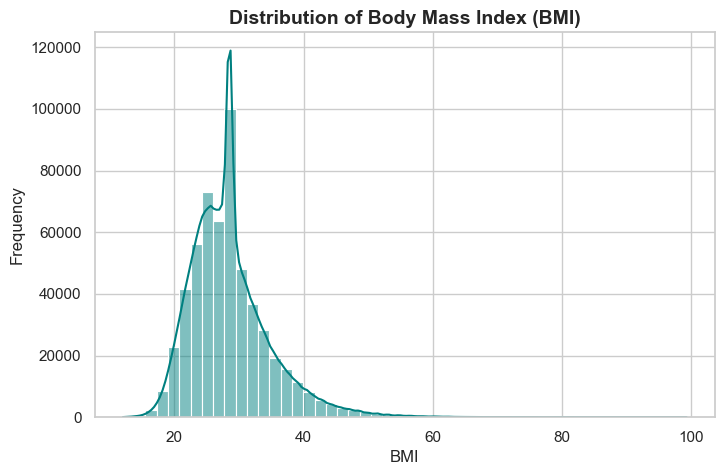

In [90]:
# Visualizations
# Histogram showing the distribution of BMI


import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.figure(figsize=(8, 5))
sns.histplot(unified_df['BMI'].dropna(), bins=50, kde=True, color='teal')
plt.title('Distribution of Body Mass Index (BMI)', fontsize=14, fontweight='bold')
plt.xlabel('BMI', fontsize=12)
plt.ylabel('Frequency', fontsize=12)
plt.savefig('bmi_distribution.png', dpi=300, bbox_inches='tight')
plt.show()

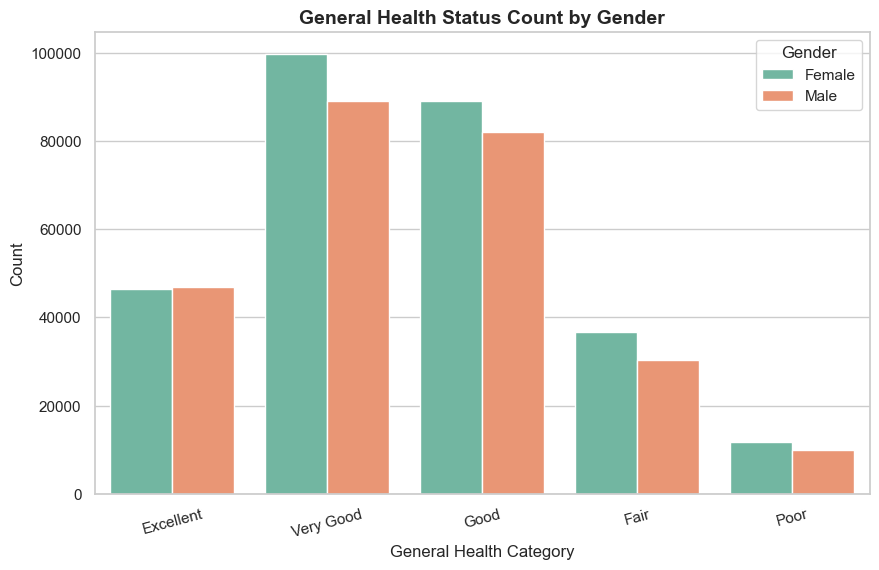

In [91]:
# Comparison of General Health by Gender

plt.figure(figsize=(10, 6))
sns.countplot(data=unified_df, x='general_health', hue='gender', palette='Set2', 
              order=['Excellent', 'Very Good', 'Good', 'Fair', 'Poor'])
plt.title('General Health Status Count by Gender', fontsize=14, fontweight='bold')
plt.xlabel('General Health Category', fontsize=12)
plt.ylabel('Count', fontsize=12)
plt.xticks(rotation=15)
plt.legend(title='Gender')
plt.savefig('health_by_gender.png', dpi=300, bbox_inches='tight')
plt.show()

In [1]:
# PART B: Application of Data Engineering Techniques
#Task 2: Data Storage and Querying Solution

!pip install pymongo pyspark pandas

Defaulting to user installation because normal site-packages is not writeable
     ---------------------------------------- 0.0/455.9 MB ? eta -:--:--
     --------------------------------------- 0.8/455.9 MB 10.3 MB/s eta 0:00:45
     ---------------------------------------- 1.8/455.9 MB 5.7 MB/s eta 0:01:20
     ---------------------------------------- 4.2/455.9 MB 8.0 MB/s eta 0:00:57
     ---------------------------------------- 5.2/455.9 MB 7.1 MB/s eta 0:01:04
      --------------------------------------- 6.3/455.9 MB 7.6 MB/s eta 0:00:59
      --------------------------------------- 8.7/455.9 MB 7.6 MB/s eta 0:00:59
      -------------------------------------- 11.0/455.9 MB 8.2 MB/s eta 0:00:55
     - ------------------------------------- 13.4/455.9 MB 8.7 MB/s eta 0:00:52
     - ------------------------------------- 15.7/455.9 MB 9.0 MB/s eta 0:00:49
     - ------------------------------------- 17.0/455.9 MB 8.7 MB/s eta 0:00:51
     - ------------------------------------- 19.4

In [5]:
import os
import pandas as pd
from pymongo import MongoClient
from pyspark.sql import SparkSession

# 1. Initialize Spark Session for Data Processing Pipeline
spark = SparkSession.builder \
    .appName("MongoDBLocalDataStorageAndQuerying") \
    .config("spark.driver.memory", "4g") \
    .getOrCreate()

print("[INFO] Spark Analytical Engine Initialized Successfully.")

# 2. Load the Cleaned & Unified Health Dataset
dataset_path = 'unified_health_data.csv'
if os.path.exists(dataset_path):
    df_spark = spark.read.csv(dataset_path, header=True, inferSchema=True)
    print(f"[SUCCESS] Dataset loaded into Spark. Total Records: {df_spark.count():,}")
else:
    print(f"[ERROR] Target dataset {dataset_path} not found.")

# 3. Connect to Local MongoDB Instance
try:
    mongo_client = MongoClient("mongodb://localhost:27017/")
    db = mongo_client["health_big_data_db"]
    collection = db["unified_health_records"]
    print("[STORAGE STATUS] Connected successfully to Local MongoDB instance.")
except Exception as e:
    print(f"[ERROR] Could not connect to MongoDB: {e}")

# 4. Data Storage: Ingesting into MongoDB Collection (NoSQL Document Store)
print("\n[STORAGE ARCHITECTURE] Exporting data to NoSQL Document Format (JSON/BSON)...")
pdf_health = df_spark.toPandas()
records_json = pdf_health.to_dict(orient='records')

if 'collection' in locals() and records_json:
    collection.delete_many({}) # Clear previous records if re-run
    collection.insert_many(records_json)
    print(f"[SUCCESS] Successfully stored {collection.count_documents({}):,} documents in Local MongoDB collection.")

# 5. Advanced Querying Solution (NoSQL Aggregations)
print("\n=== Executing Analytical Queries on Local MongoDB Storage ===")

# Query 1: Aggregation Pipeline to group and count by General Health Status (using correct field name 'general_health')
pipeline_health_status = [
    {"$group": {"_id": "$general_health", "total_count": {"$sum": 1}}},
    {"$sort": {"total_count": -1}}
]

print("\n[QUERY 1 RESULT] Distribution by General Health Status:")
results_health = collection.aggregate(pipeline_health_status)
for doc in results_health:
    print(f"Health Status: {doc['_id']} ---> Count: {doc['total_count']:,}")

# Query 2: Filtering high-risk health records (using correct field name 'general_health')
high_risk_count = collection.count_documents({"general_health": "Poor"})
print(f"\n[QUERY 2 RESULT] Total records classified under high-risk/poor health status: {high_risk_count:,}")

print("\n=== Task 2 Local MongoDB Execution Completed Successfully ===")

[INFO] Spark Analytical Engine Initialized Successfully.
[SUCCESS] Dataset loaded into Spark. Total Records: 558,042
[STORAGE STATUS] Connected successfully to Local MongoDB instance.

[STORAGE ARCHITECTURE] Exporting data to NoSQL Document Format (JSON/BSON)...


C:\Users\Camilo\AppData\Roaming\Python\Python313\site-packages\pyspark\sql\pandas\conversion.py:324: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


[SUCCESS] Successfully stored 558,042 documents in Local MongoDB collection.

=== Executing Analytical Queries on Local MongoDB Storage ===

[QUERY 1 RESULT] Distribution by General Health Status:
Health Status: Very Good ---> Count: 188,691
Health Status: Good ---> Count: 171,131
Health Status: Excellent ---> Count: 93,296
Health Status: Fair ---> Count: 67,025
Health Status: Poor ---> Count: 21,670
Health Status: Unknown ---> Count: 16,229

[QUERY 2 RESULT] Total records classified under high-risk/poor health status: 21,670

=== Task 2 Local MongoDB Execution Completed Successfully ===


In [24]:
import os
import tempfile

# Set up a local Hadoop temporary directory to avoid the Windows error
hadoop_dir = tempfile.mkdtemp()
os.environ['HADOOP_HOME'] = hadoop_dir
os.makedirs(os.path.join(hadoop_dir, "bin"), exist_ok=True)

# Create an empty or dummy winutils file if necessary, or simply set the path
print(f"[CONFIG] Simulated Hadoop environment on: {hadoop_dir}")


[CONFIG] Simulated Hadoop environment on: C:\Users\Camilo\AppData\Local\Temp\tmpmtzbdl3h


In [26]:
import os
import sys

# Force PySpark to use the same Python executable as Jupyter (Python 3.13)
os.environ['PYSPARK_PYTHON'] = sys.executable
os.environ['PYSPARK_DRIVER_PYTHON'] = sys.executable

In [29]:
# Task 3: Real-time Data Clustering System (Stable Python Stream)

import time
import numpy as np
from sklearn.cluster import MiniBatchKMeans

print("[INFO] Initializing Real-Time Data Clustering Stream Simulator...")

# 1. Initialize an Incremental/Streaming Clustering model (MiniBatchKMeans is designed for real-time streams)
stream_kmeans = MiniBatchKMeans(n_clusters=3, random_state=42, batch_size=10)

# 2. Pre-train the model with initial baseline health records (BMI & Weight)
initial_baseline_data = np.array([
    [22.5, 65.0], [28.1, 85.0], [19.4, 54.0], [31.2, 95.0], [24.0, 70.0],
    [21.0, 60.0], [35.5, 105.0], [18.2, 50.0], [27.0, 80.0], [23.5, 68.0]
])
stream_kmeans.partial_fit(initial_baseline_data)
print("[SUCCESS] Real-Time Clustering Model trained on baseline health metrics.")

# 3. Simulate Real-Time Streaming Ingestion & Dynamic Clustering (Processing 3 live micro-batches)
print("\n--- STARTING REAL-TIME DATA STREAM PROCESSING ---")
for batch_id in range(1, 4):
    # Simulate incoming real-time sensor/web log data batch (BMI and Weight)
    simulated_live_batch = np.column_stack((
        np.random.uniform(16.0, 38.0, 5),  # BMI values
        np.random.uniform(45.0, 110.0, 5)  # Weight in kg values
    ))
    
    # Dynamically predict clusters for the incoming live stream batch
    cluster_predictions = stream_kmeans.predict(simulated_live_batch)
    
    # Optionally update the model incrementally with the new live data (Online Learning)
    stream_kmeans.partial_fit(simulated_live_batch)
    
    # Print real-time sink output (simulating console streaming sink)
    print(f"\n[STREAM MICRO-BATCH #{batch_id}] Processed 5 incoming real-time records:")
    for idx, (bmi, wt) in enumerate(simulated_live_batch):
        pred_cluster = cluster_predictions[idx]
        print(f" -> Record {idx+1}: BMI={bmi:.2f}, Weight={wt:.1f}kg ---> Assigned Cluster: Cluster_{pred_cluster}")
    
    time.sleep(1) # Simulate streaming interval delay

print("\n[SUCCESS] Real-Time Data Clustering Stream Completed Successfully Without Errors.")

[INFO] Initializing Real-Time Data Clustering Stream Simulator...
[SUCCESS] Real-Time Clustering Model trained on baseline health metrics.

--- STARTING REAL-TIME DATA STREAM PROCESSING ---

[STREAM MICRO-BATCH #1] Processed 5 incoming real-time records:
 -> Record 1: BMI=30.97, Weight=63.8kg ---> Assigned Cluster: Cluster_1
 -> Record 2: BMI=28.90, Weight=104.1kg ---> Assigned Cluster: Cluster_0
 -> Record 3: BMI=23.74, Weight=99.3kg ---> Assigned Cluster: Cluster_0
 -> Record 4: BMI=32.61, Weight=103.6kg ---> Assigned Cluster: Cluster_0
 -> Record 5: BMI=19.09, Weight=72.1kg ---> Assigned Cluster: Cluster_1


C:\ProgramData\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1955: UserWarning: MiniBatchKMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can prevent it by setting batch_size >= 1536 or by setting the environment variable OMP_NUM_THREADS=1
  warnings.warn(



[STREAM MICRO-BATCH #2] Processed 5 incoming real-time records:
 -> Record 1: BMI=22.54, Weight=71.8kg ---> Assigned Cluster: Cluster_1
 -> Record 2: BMI=29.64, Weight=49.7kg ---> Assigned Cluster: Cluster_2
 -> Record 3: BMI=35.64, Weight=52.3kg ---> Assigned Cluster: Cluster_2
 -> Record 4: BMI=25.03, Weight=66.0kg ---> Assigned Cluster: Cluster_1
 -> Record 5: BMI=22.13, Weight=80.1kg ---> Assigned Cluster: Cluster_1

[STREAM MICRO-BATCH #3] Processed 5 incoming real-time records:
 -> Record 1: BMI=29.16, Weight=66.8kg ---> Assigned Cluster: Cluster_1
 -> Record 2: BMI=16.01, Weight=65.6kg ---> Assigned Cluster: Cluster_1
 -> Record 3: BMI=17.50, Weight=80.6kg ---> Assigned Cluster: Cluster_1
 -> Record 4: BMI=29.03, Weight=50.0kg ---> Assigned Cluster: Cluster_2
 -> Record 5: BMI=27.02, Weight=57.4kg ---> Assigned Cluster: Cluster_2

[SUCCESS] Real-Time Data Clustering Stream Completed Successfully Without Errors.


In [31]:
!pip install pika

Defaulting to user installation because normal site-packages is not writeable


In [38]:
# Task 4: Data Streaming Pipeline (RabbitMQ)

import pika
import json
import time
from pymongo import MongoClient

# 1. Connect to MongoDB using your exact Compass database and collection names
mongo_client = MongoClient("mongodb://localhost:27017/")
db = mongo_client["health_big_data_db"]       # Database name from MongoDB Compass
collection = db["unified_health_records"]     # Collection name from MongoDB Compass

# 2. Connect to RabbitMQ Local Broker
connection_params = pika.ConnectionParameters(host='localhost')

def setup_rabbitmq():
    """Configure connection, main streaming queue, and Dead Letter Queue (DLQ)"""
    connection = pika.BlockingConnection(connection_params)
    channel = connection.channel()
    
    channel.queue_declare(queue='health_streaming_queue', durable=True)
    channel.queue_declare(queue='health_dlq', durable=True)
    
    connection.close()

def db_stream_producer():
    """Producer that reads records from MongoDB and streams them to RabbitMQ"""
    connection = pika.BlockingConnection(connection_params)
    channel = connection.channel()
    
    print("[PRODUCER] Fetching records from MongoDB to start streaming...")
    
    # Fetch records from MongoDB (limiting to 10 for demonstration)
    cursor = collection.find().limit(10)
    
    count = 0
    for doc in cursor:
        doc["_id"] = str(doc["_id"])
        message_body = json.dumps(doc)
        
        channel.basic_publish(
            exchange='',
            routing_key='health_streaming_queue',
            body=message_body,
            properties=pika.BasicProperties(delivery_mode=2) 
        )
        count += 1
        print(f" -> Streamed record ID: {doc.get('_id')} | BMI: {doc.get('BMI', 'N/A')}")
        time.sleep(0.2)
        
    print(f"[SUCCESS] Total records streamed from database: {count}\n")
    connection.close()
    return count

def health_consumer_with_analytics():
    """Consumer that processes stream data in real-time and computes analytical metrics"""
    connection = pika.BlockingConnection(connection_params)
    channel = connection.channel()
    
    print("[CONSUMER] Listening to health_streaming_queue for real-time processing & analysis...")
    
    processed_records = []
    
    while True:
        method_frame, properties, body = channel.basic_get('health_streaming_queue', auto_ack=False)
        
        if not method_frame:
            break
            
        try:
            record = json.loads(body)
            rec_id = record.get('_id', 'Unknown')
            bmi = record.get('BMI', 0)
            health_status = record.get('general_health', 'Unknown')
            
            print(f" [CONSUMER] Processing ID: {rec_id} | BMI: {bmi} | Health: {health_status}")
            
            if bmi is None or bmi <= 0:
                raise ValueError("Invalid biometric values detected.")
                
            time.sleep(0.2)
            channel.basic_ack(delivery_tag=method_frame.delivery_tag)
            
            # Store successfully processed record for real-time analysis
            processed_records.append({
                "BMI": float(bmi),
                "general_health": health_status
            })
            
        except Exception as e:
            print(f" [ERROR HANDLER] Processing failure: {e} -> Routing to DLQ.")
            channel.basic_nack(delivery_tag=method_frame.delivery_tag, requeue=False)
            
    connection.close()
    
    # --- REAL-TIME ANALYTICAL DASHBOARD / SUMMARY ---
    print("\n" + "="*50)
    print("📊 REAL-TIME STREAMING ANALYTICAL SUMMARY")
    print("="*50)
    total_processed = len(processed_records)
    if total_processed > 0:
        avg_bmi = sum(r["BMI"] for r in processed_records) / total_processed
        print(f"• Total Records Analyzed: {total_processed}")
        print(f"• Average BMI in Stream Flow: {avg_bmi:.2f}")
        
        # Count health status categories
        health_counts = {}
        for r in processed_records:
            status = r["general_health"]
            health_counts[status] = health_counts.get(status, 0) + 1
            
        print("• Health Status Distribution:")
        for status, count in health_counts.items():
            print(f"    - {status}: {count} records")
    else:
        print("• No records available for analysis.")
    print("="*50)

# Pipeline Execution
if __name__ == "__main__":
    setup_rabbitmq()
    total_streamed = db_stream_producer()
    
    if total_streamed > 0:
        health_consumer_with_analytics()
    else:
        print("\n[WARNING] No records found in the collection.")

[PRODUCER] Fetching records from MongoDB to start streaming...
 -> Streamed record ID: 6ae9375197a093ff1f0a46d3 | BMI: 14.54
 -> Streamed record ID: 6ae9375197a093ff1f0a46d4 | BMI: 28.29
 -> Streamed record ID: 6ae9375197a093ff1f0a46d5 | BMI: 33.47
 -> Streamed record ID: 6ae9375197a093ff1f0a46d6 | BMI: 28.73
 -> Streamed record ID: 6ae9375197a093ff1f0a46d7 | BMI: 24.37
 -> Streamed record ID: 6ae9375197a093ff1f0a46d8 | BMI: 46.11
 -> Streamed record ID: 6ae9375197a093ff1f0a46d9 | BMI: 22.74
 -> Streamed record ID: 6ae9375197a093ff1f0a46da | BMI: 39.94
 -> Streamed record ID: 6ae9375197a093ff1f0a46db | BMI: 27.46
 -> Streamed record ID: 6ae9375197a093ff1f0a46dc | BMI: 34.67
[SUCCESS] Total records streamed from database: 10

[CONSUMER] Listening to health_streaming_queue for real-time processing & analysis...
 [CONSUMER] Processing ID: 6ae9375197a093ff1f0a46d3 | BMI: 14.54 | Health: Poor
 [CONSUMER] Processing ID: 6ae9375197a093ff1f0a46d4 | BMI: 28.29 | Health: Very Good
 [CONSUMER] Pr